## Plotting lightcurve

In [2]:
import matplotlib.pyplot as plt
from astropy.time import Time
import numpy as np

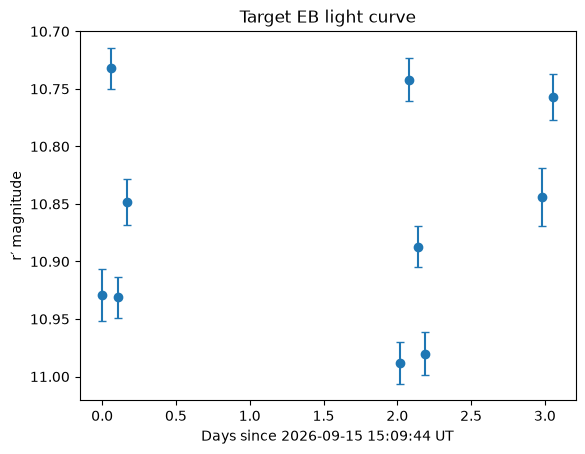

In [3]:
times = ["2026-09-15 15:09:44","2026-09-15 16:31:52","2026-09-15 17:47:52","2026-09-15 19:09:52",
         "2026-09-17 15:37:52","2026-09-17 17:01:52","2026-09-17 18:31:52","2026-09-17 19:37:52",
         "2026-09-18 14:45:52","2026-09-18 16:29:52"]
mag = np.array([10.929,10.732,10.931,10.848,10.988,10.742,10.887,10.980,10.844,10.757])
err = np.array([0.0227,0.0178,0.0178,0.0200,0.0182,0.0185,0.0178,0.0189,0.0250,0.0200])

jd = Time(times, scale="utc").jd
t = jd - jd[0]   #days since first image

plt.errorbar(t, mag, yerr=err, fmt="o", capsize=3)
plt.gca().invert_yaxis()
plt.xlabel("Days since 2026-09-15 15:09:44 UT")
plt.ylabel("r′ magnitude")
plt.title("Target EB light curve")
# plt.savefig("lightcurve.png", dpi=150)
plt.show()

## Finding Period using Lomb Scargle Method

In [10]:
w = 1/err**2

m_bar = np.sum(mag*w)/np.sum(w)
chi2_0 = np.sum(w*(mag-m_bar)**2)


#frequency grid
fmin, fmax, df = 24/120, 24/0.8, 1/(200*t.max())
freqs = np.arange(fmin, fmax, df)

In [11]:
def sine_fit(f):
    X = np.column_stack((np.ones_like(t), np.sin(2*np.pi*f*t), np.cos(2*np.pi*f*t)))
    sw = np.sqrt(w)
    coef, *_ = np.linalg.lstsq(X*sw[:,None], mag*sw, rcond=None)
    model = X @coef
    chi2 = np.sum(w*(mag-model)**2)
    return chi2, coef

power = np.array([1 - sine_fit(f)[0]/chi2_0 for f in freqs])

In [12]:
best_f = freqs[np.argmax(power)]
print("Sine Period:", 24/best_f, "hours")
print("EB period:", 2*(24/best_f), "hours")

Sine Period: 3.764440612415189 hours
EB period: 7.528881224830378 hours


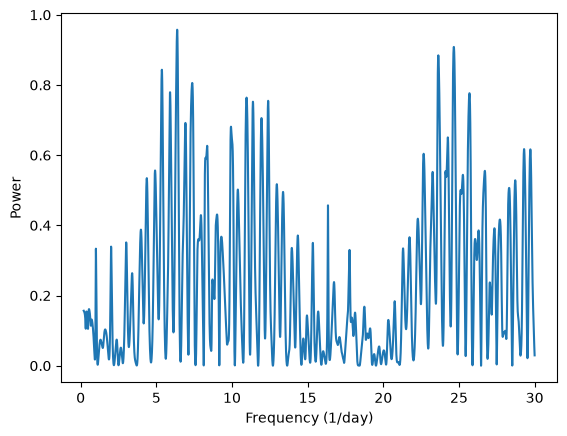

In [13]:
plt.plot(freqs, power)
plt.xlabel("Frequency (1/day)")
plt.ylabel("Power")
plt.show()

In [14]:
# 1. Find local peaks: points higher than both neighbours
is_peak = (power[1:-1] > power[:-2]) & (power[1:-1] > power[2:])
idx = np.where(is_peak)[0] + 1

# 2. Sort them from strongest to weakest
idx = idx[np.argsort(power[idx])[::-1]]

# 3. Print the top N
N = 5
best_f = freqs[idx[0]]
print(f"{'Rank':>4} {'Power':>6} {'Sine P (h)':>11} {'EB P (h)':>9} {'f (c/d)':>8}  Note")
for rank, i in enumerate(idx[:N], 1):
    f = freqs[i]
    df = f - best_f
    k = round(df)
    note = "best" if rank == 1 else (f"{k:+d} c/d alias" if k != 0 and abs(df - k) < 0.08 else "")
    print(f"{rank:>4} {power[i]:6.3f} {24/f:11.3f} {48/f:9.3f} {f:8.3f}  {note}")

Rank  Power  Sine P (h)  EB P (h)  f (c/d)  Note
   1  0.958       3.764     7.529    6.375  best
   2  0.908       0.973     1.947   24.660  
   3  0.884       1.016     2.031   23.634  
   4  0.844       4.474     8.948    5.364  -1 c/d alias
   5  0.806       3.256     6.513    7.370  +1 c/d alias


In [19]:
fg = np.arange(best_f - 0.3, best_f+0.3, 0.002)
mag0, P = mag.copy(), []

for _ in range(1000):
    mag = mag0 + np.random.normal(0,err)
    P.append(48/fg[np.argmin([sine_fit(f)[0] for f in fg])])
    # print(sine_fit(best_f)[0])

mag = mag0
print(f"EB period = {np.mean(P):.4f}  ± {np.std(P):.4f} h ")

EB period = 7.5279  ± 0.0109 h 


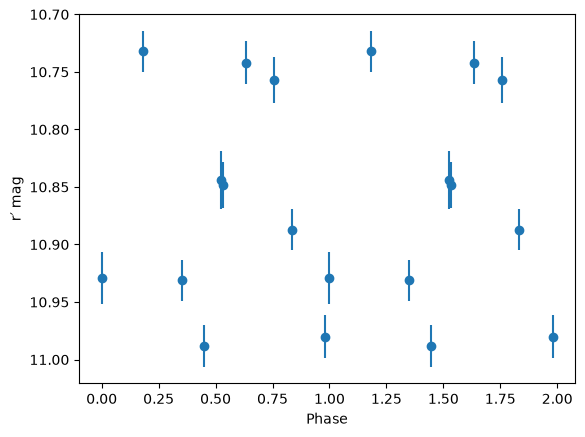

In [24]:
EB_period = 2*(1/best_f)  #days
phase = (t/EB_period)%1

plt.errorbar(np.r_[phase, phase+1], np.r_[mag, mag],
             yerr=np.r_[err, err], fmt="o")
plt.gca().invert_yaxis()
plt.xlabel("Phase"); plt.ylabel("r′ mag")
plt.show()